## Problem Statement

#### AIM :To build a machine learning model to predict whether a person is diabetic or non-diabetic

## Import Library

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,classification_report,ConfusionMatrixDisplay
import warnings
warnings.filterwarnings("ignore")

### Load dataset

In [2]:
df = pd.read_csv("diabetes_prediction_dataset.csv")

## Data Overview

### First five rows of dataset

In [3]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [4]:
df.dtypes

gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

### Column description

**gender:** Gender of the person (Male/Female/Other)

**age:** Age of the person in years

**hypertension:** Indicates whether the person has high blood pressure (1 = Yes, 0 = No)

**heart_disease:** Indicates whether the person has any heart disease (1 = Yes, 0 = No)

**smoking_history:** Smoking status of the person (e.g., never, former, current, not current)

**bmi:** Body Mass Index, a measure of body fat based on height and weight

**HbA1c_level:** Average blood sugar level over the past 2–3 months

**blood_glucose_level:** Current blood glucose (sugar) level in the blood

**diabetes:** Target variable indicating whether the person has diabetes (1 = Yes, 0 = No)

### Datatype of each columns

In [5]:
df.dtypes

gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

### Shape of data

In [6]:
df.shape

(100000, 9)

### Information of each columns

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


### Describe of each columns

In [8]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


### Check null value

In [9]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

### Check duplicate value

In [10]:
df.duplicated().sum()

np.int64(3854)

### Drop duplicate

In [11]:
df.drop_duplicates(inplace=True)

## EDA

In [12]:
num_cols = ["age","bmi","HbA1c_level","blood_glucose_level"]
cat_cols = ["gender","hypertension","heart_disease","smoking_history"]
target = ["diabetes"]

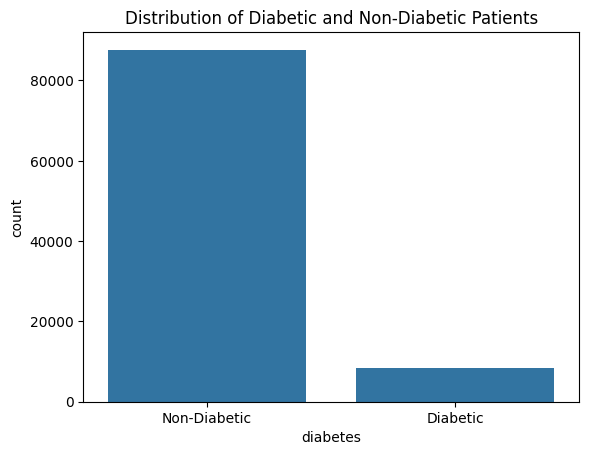

In [13]:
sns.countplot(data=df,x="diabetes")
plt.xticks([0, 1], ["Non-Diabetic", "Diabetic"])
plt.title("Distribution of Diabetic and Non-Diabetic Patients")
plt.show()

<Axes: xlabel='gender', ylabel='count'>

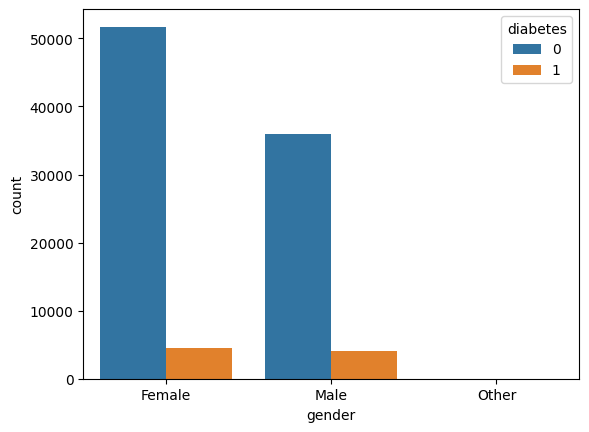

In [14]:
sns.countplot(data=df,x="gender",hue="diabetes")

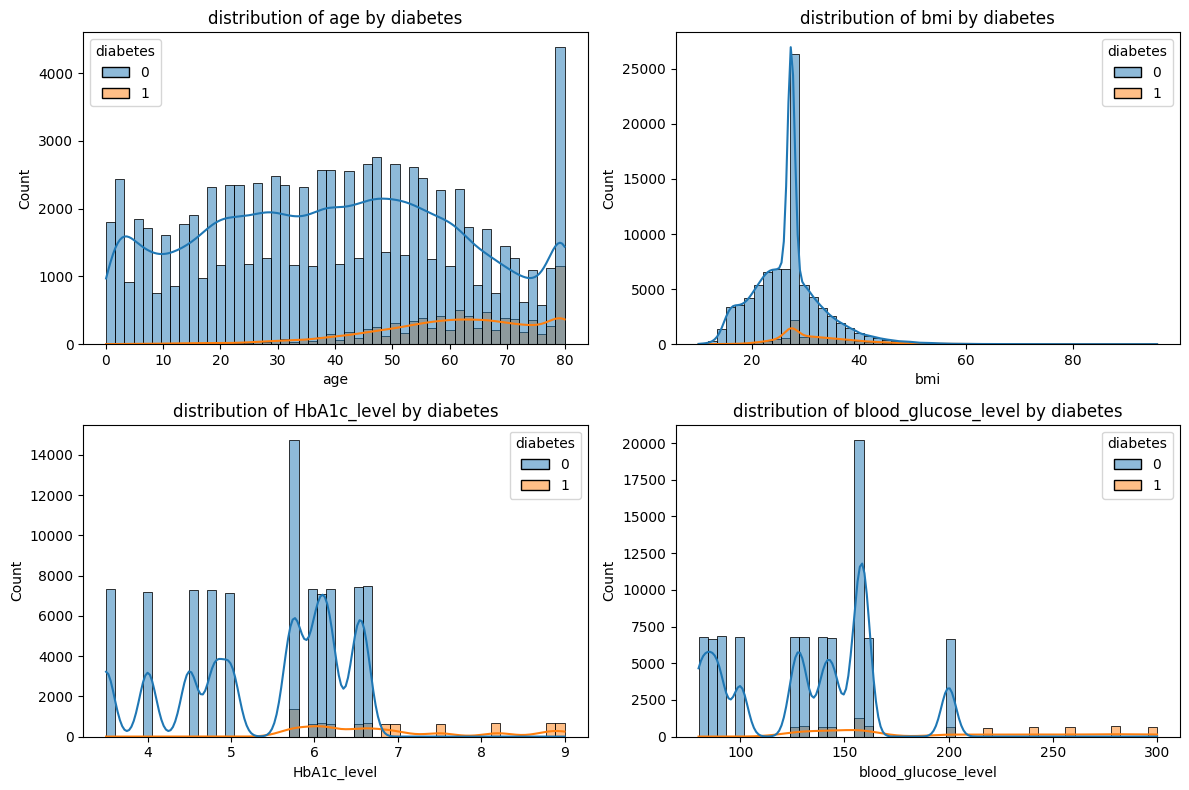

In [15]:
plt.figure(figsize=(12,8))
for i,col in enumerate(num_cols,1):
    plt.subplot(2,2,i)
    plt.title(f"distribution of {col} by diabetes")
    sns.histplot(data=df,x=col,bins=50,kde=True,hue="diabetes")
plt.tight_layout()
plt.show()

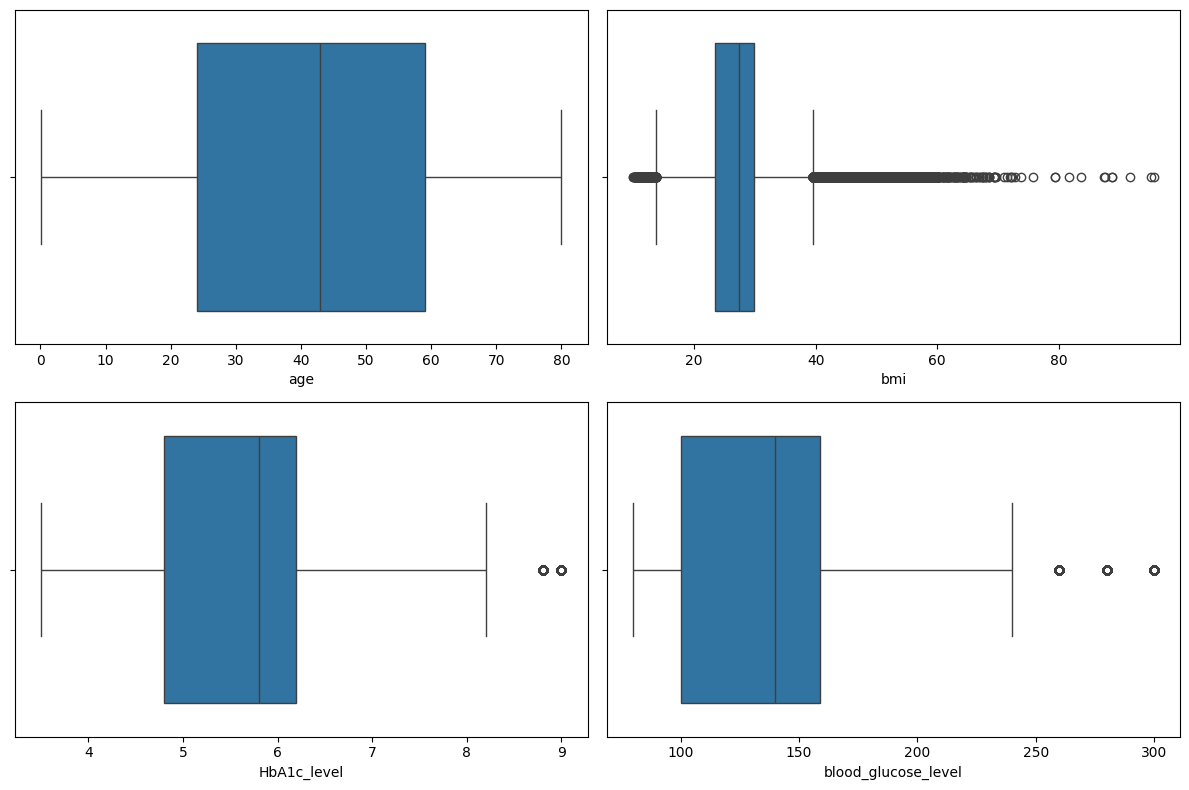

In [16]:
plt.figure(figsize=(12,8))
for i,col in enumerate(num_cols,1):
    plt.subplot(2,2,i)
    sns.boxplot(data=df,x=col)
plt.tight_layout()
plt.show()

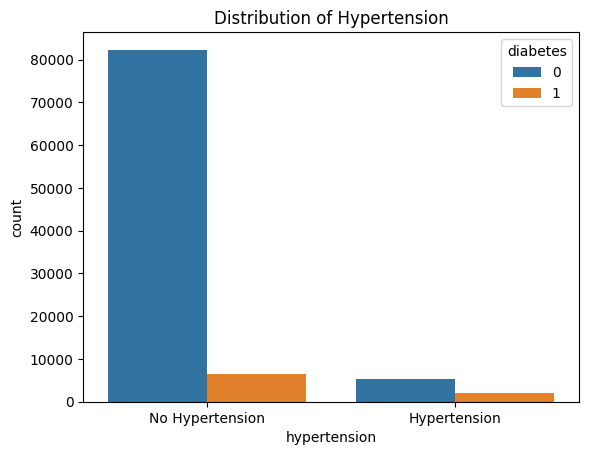

In [17]:
sns.countplot(data=df,x="hypertension",hue="diabetes")
plt.xticks([0,1],["No Hypertension","Hypertension"])
plt.title("Distribution of Hypertension")
plt.show()

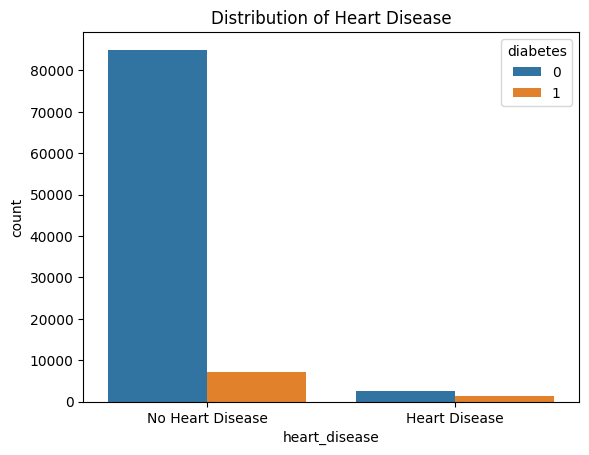

In [18]:
sns.countplot(data=df,x="heart_disease",hue="diabetes")
plt.xticks([0, 1], ["No Heart Disease", "Heart Disease"])
plt.title("Distribution of Heart Disease")
plt.show()

<Axes: xlabel='smoking_history', ylabel='count'>

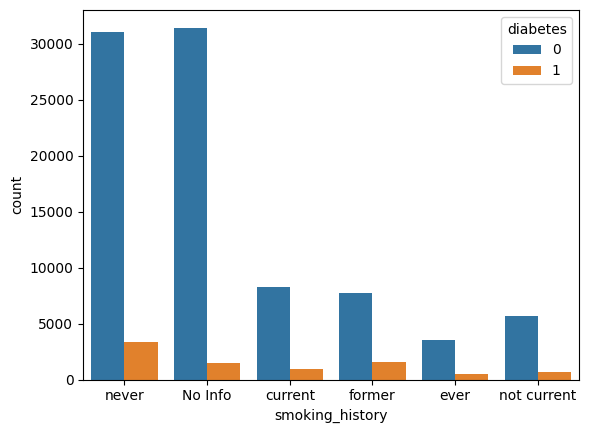

In [19]:
sns.countplot(data=df,x="smoking_history",hue="diabetes")

### Insights :

- **There are more non-diabetic people than diabetic people.This means the data is imbalanced,so we used SMOTE later in model building.**
  
- **From the gender plot, both males and females have diabetes,but males have slightly more diabetic cases.**

- **People with high HbA1c level and high blood glucose level are mostly diabetic. These are the strongest indicators of diabetes.**

- **People with higher BMI have more chances of having diabetes.**

- **People with hypertension show more diabetic cases.**

- **Current and former smokers show a higher proportion of diabetes than never smokers.**

## Model Building

In [20]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [21]:
X = df.drop("diabetes",axis=1)
y = df["diabetes"]

In [22]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [23]:
preprocessor = ColumnTransformer([
    ("num",StandardScaler(),num_cols),
    ("cat",OneHotEncoder(drop="first",handle_unknown="ignore"),cat_cols)
],remainder="passthrough")

In [24]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000,random_state=42),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=50,n_jobs=-1,random_state=42),
    "GradientBoost": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42,eval_metric="logloss")
}

In [25]:
for name,model in models.items():
    pipe = Pipeline([
        ("preprocessing",preprocessor),
        ("smote",SMOTE(random_state=42)),
        ("model",model)
    ])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    acc = accuracy_score(y_test,y_pred)
    

In [26]:
for name,model in models.items():
    pipe = Pipeline([
        ("preprocessing",preprocessor),
        ("smote",SMOTE(random_state=42)),
        ("model",model)
    ])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    acc = accuracy_score(y_test,y_pred)
    print(f"-----------------------------------{name}-------------------------------------")
    print(f"accuracy : {acc:.4f}")
    cv_scores = cross_val_score(pipe,X,y,cv=5,scoring="accuracy")
    print(f"CV Average : {cv_scores.mean() : .4f}")
    print(f"ROC AUC : {roc_auc_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred))

-----------------------------------LogisticRegression-------------------------------------
accuracy : 0.8859
CV Average :  0.8862
ROC AUC : 0.8870
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17509
           1       0.43      0.89      0.58      1721

    accuracy                           0.89     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.89      0.90     19230

-----------------------------------DecisionTree-------------------------------------
accuracy : 0.9454
CV Average :  0.9447
ROC AUC : 0.8568
              precision    recall  f1-score   support

           0       0.98      0.96      0.97     17509
           1       0.68      0.75      0.71      1721

    accuracy                           0.95     19230
   macro avg       0.83      0.86      0.84     19230
weighted avg       0.95      0.95      0.95     19230

-----------------------------------RandomForest-----------

## Conclusion

**Here,XGBoost achieved the highest accuracy (96%),but its recall for diabetic patients was only 0.72,that means it missed 28% of diabetics.Gradient Boosting had slightly lower accuracy (95%) but a higher recall of 0.78 and a good F1-score of 0.75, with ROC-AUC of 0.87. Since detecting diabetic patients is more important than accuracy, Gradient Boosting was selected as the final model.**

**Final Model : Gradient Boosting**

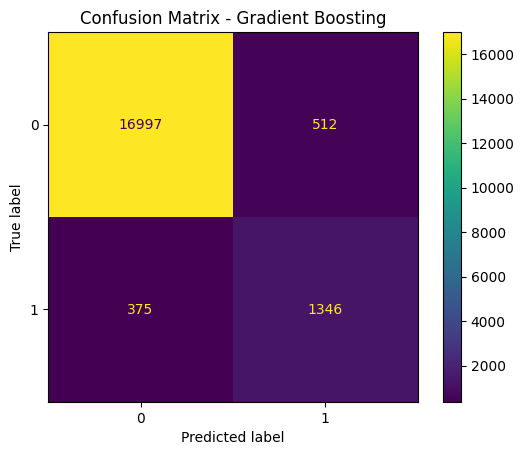

In [27]:
final_model = GradientBoostingClassifier(random_state=42)

final_pipe = Pipeline([
    ("preprocessing", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", final_model)
])

final_pipe.fit(X_train, y_train)

from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(final_pipe, X_test, y_test)
plt.title("Confusion Matrix - Gradient Boosting")
plt.show()

In [28]:
import joblib
model = joblib.dump(final_pipe,"model.pkl")